# Breast Cancer Classification: логистическая регрессия с нуля

Диагностика рака молочной железы по 30 числовым признакам (датасет `load_breast_cancer` из scikit-learn, 569 пациентов).

**Что делаем:**
- реализуем логистическую регрессию с L2-регуляризацией и мини-батч SGD на чистом NumPy, в стиле scikit-learn;
- сверяем реализацию с `sklearn.linear_model.LogisticRegression`;
- исследуем влияние шага обучения (`lr`) и коэффициента регуляризации (`alpha`), в том числе условие устойчивости обучения;
- выбираем `alpha` кросс-валидацией (`KFold` и `ShuffleSplit`) и сравниваем дисперсию двух стратегий;
- оцениваем итоговую модель с точки зрения медицинской задачи: важнее всего не пропустить опухоль.

## 1. Импорты

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import (confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.model_selection import (KFold, ShuffleSplit, cross_val_predict,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 2. Данные

**Важная деталь про метки.** В этом датасете `target = 0` означает *злокачественную* опухоль, а `target = 1` — *доброкачественную*. Все метрики scikit-learn по умолчанию считаются для класса `1`. Поэтому без дополнительных действий `recall` отвечал бы на вопрос «какую долю доброкачественных опухолей мы нашли», а нас интересует обратное.

Чтобы не ошибиться, инвертируем метки: пусть `1` — злокачественная опухоль (положительный класс — то, что мы хотим находить). Тогда стандартные метрики автоматически считаются по нужному классу.

In [2]:
dataset = load_breast_cancer()
X = dataset.data
y = (dataset.target == 0).astype(int)   # 1 = злокачественная, 0 = доброкачественная

print(f"Объектов: {X.shape[0]}, признаков: {X.shape[1]}")
print(f"Злокачественных (1): {y.sum()}, доброкачественных (0): {(y == 0).sum()}")

Объектов: 569, признаков: 30
Злокачественных (1): 212, доброкачественных (0): 357


Классы не идеально сбалансированы (злокачественных примерно 37%), поэтому разбиение на train и test делаем со стратификацией.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (455, 30), Test: (114, 30)


## 3. Метрики

В медицинской задаче цена ошибок несимметрична. Пропущенная опухоль (ложноотрицательный ответ, FN) может стоить жизни, а ложная тревога (FP) означает лишь дополнительное обследование. Поэтому главная метрика — **recall** (полнота): какую долю больных мы обнаружили.

Но recall = 1 тривиально достигается, если всем пациентам ставить «опухоль». Чтобы такая модель не считалась хорошей, смотрим и на **precision** (какая доля тревог оказалась настоящей), а для выбора гиперпараметров используем **F1**, которая объединяет оба показателя.

Данные нужно стандартизовать, иначе регуляризация будет штрафовать признаки по-разному из-за масштаба. `StandardScaler` включаем в `Pipeline`, чтобы при кросс-валидации он настраивался только на обучающей части каждого фолда.

## 4. Модель

Логистическая регрессия предсказывает вероятность злокачественной опухоли $p(x) = \sigma(x^\top w + b)$ и минимизирует

$$
F(w, b) = \frac{1}{n}\sum_{i=1}^{n}\Big[\log\big(1 + e^{z_i}\big) - y_i z_i\Big] + \frac{\alpha}{2}\|w\|_2^2, \qquad z_i = x_i^\top w + b.
$$

Свободный член $b$ не регуляризуется. Градиент на мини-батче $B$:

$$
\nabla_w = \frac{1}{|B|}\sum_{i \in B} \big(\sigma(z_i) - y_i\big)\, x_i + \alpha w, \qquad
\nabla_b = \frac{1}{|B|}\sum_{i \in B} \big(\sigma(z_i) - y_i\big).
$$

Шаг обновления с регуляризацией можно записать как $w \leftarrow (1 - \text{lr}\cdot\alpha)\, w - \text{lr}\cdot\nabla_{\text{loss}}$. Отсюда видно условие устойчивости: если $\text{lr}\cdot\alpha > 2$, то множитель $|1 - \text{lr}\cdot\alpha|$ больше единицы, и веса растут экспоненциально. Ниже проверим это экспериментально.

Для воспроизводимости случайный выбор батчей управляется параметром `random_state`.

In [4]:
class SGDLogisticRegression(ClassifierMixin, BaseEstimator):
    """Логистическая регрессия с L2-регуляризацией, обученная мини-батч SGD.

    Параметры
    ---------
    alpha : коэффициент L2-регуляризации (0 — без регуляризации)
    lr : шаг градиентного спуска
    max_iter : число итераций (батчей)
    batch_size : размер мини-батча
    fit_intercept : добавлять ли свободный член (он не регуляризуется)
    random_state : seed для выбора батчей
    record_every : если > 0, каждые record_every итераций сохраняет значение функции потерь
    """

    def __init__(self, alpha=0.0, lr=0.1, max_iter=5000, batch_size=32,
                 fit_intercept=True, random_state=None, record_every=0):
        self.alpha = alpha
        self.lr = lr
        self.max_iter = max_iter
        self.batch_size = batch_size
        self.fit_intercept = fit_intercept
        self.random_state = random_state
        self.record_every = record_every

    def _design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        if self.fit_intercept:
            return np.hstack([X, np.ones((X.shape[0], 1))])
        return X

    def _loss(self, X_design, y):
        z = X_design @ self.weights_
        log_loss = np.mean(np.logaddexp(0, z) - y * z)
        w = self.weights_[:-1] if self.fit_intercept else self.weights_
        return log_loss + 0.5 * self.alpha * np.sum(w ** 2)

    def fit(self, X, y):
        X_design = self._design_matrix(X)
        y = np.asarray(y, dtype=float)
        if X_design.shape[0] != y.shape[0]:
            raise ValueError("X и y должны содержать одинаковое число объектов")
        if not set(np.unique(y)) <= {0.0, 1.0}:
            raise ValueError("Метки должны быть 0 или 1")
        if self.lr * self.alpha >= 2:
            warnings.warn(f"lr * alpha = {self.lr * self.alpha:.2f} >= 2: "
                          "обучение неустойчиво, веса могут расходиться")

        self.classes_ = np.array([0, 1])
        n_objects, n_params = X_design.shape
        batch_size = min(self.batch_size, n_objects)
        rng = np.random.default_rng(self.random_state)

        self.weights_ = np.zeros(n_params)
        self.loss_history_ = []

        for step in range(1, int(self.max_iter) + 1):
            idx = rng.choice(n_objects, size=batch_size, replace=False)
            X_batch, y_batch = X_design[idx], y[idx]

            grad = X_batch.T @ (expit(X_batch @ self.weights_) - y_batch) / batch_size
            reg = self.alpha * self.weights_
            if self.fit_intercept:
                reg[-1] = 0.0          # свободный член не регуляризуем
            self.weights_ -= self.lr * (grad + reg)

            if self.record_every and step % self.record_every == 0:
                self.loss_history_.append((step, self._loss(X_design, y)))

        if self.fit_intercept:
            self.coef_, self.intercept_ = self.weights_[:-1], self.weights_[-1]
        else:
            self.coef_, self.intercept_ = self.weights_, 0.0
        return self

    def predict_proba(self, X):
        p = expit(self._design_matrix(X) @ self.weights_)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def make_pipeline(**params):
    """Стандартизация + наша логистическая регрессия."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SGDLogisticRegression(random_state=SEED, **params)),
    ])

### Проверка корректности

Сравним нашу реализацию с `sklearn.linear_model.LogisticRegression`. Функции потерь связаны так: sklearn минимизирует $C\sum_i \text{loss}_i + \tfrac{1}{2}\|w\|^2$, а у нас потеря усреднена по объектам, поэтому $C = \frac{1}{n\alpha}$. Сравнение делаем на обучающей выборке, чтобы не использовать тест.

In [5]:
alpha_check = 1e-3
n_train = len(X_train)

ours = make_pipeline(alpha=alpha_check, lr=0.1, max_iter=10000).fit(X_train, y_train)
reference = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SklearnLogisticRegression(C=1 / (n_train * alpha_check), max_iter=10000)),
]).fit(X_train, y_train)

agreement = (ours.predict(X_train) == reference.predict(X_train)).mean()
coef_corr = np.corrcoef(ours[-1].coef_, reference[-1].coef_[0])[0, 1]
print(f"Совпадение предсказаний на train: {agreement:.1%}")
print(f"Корреляция коэффициентов: {coef_corr:.3f}")

Совпадение предсказаний на train: 99.8%
Корреляция коэффициентов: 0.996


Предсказания практически совпадают, а коэффициенты сильно скоррелированы. Небольшое расхождение ожидаемо: SGD на мини-батчах не доходит до точного минимума, а `LogisticRegression` из sklearn решает задачу точно.

## 5. Влияние шага обучения (`lr`)

Обучаем модели с одинаковым числом итераций и оцениваем качество 5-fold кросс-валидацией **на обучающей выборке** (тест не трогаем).

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["f1", "recall", "precision"]

lrs = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 0.3, 1, 2, 5, 10]
rows = []
for lr in lrs:
    res = cross_validate(make_pipeline(alpha=0.01, lr=lr, max_iter=5000),
                         X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"lr": lr,
                 "F1": res["test_f1"].mean(), "F1 std": res["test_f1"].std(),
                 "recall": res["test_recall"].mean(),
                 "precision": res["test_precision"].mean()})

lr_table = pd.DataFrame(rows)
lr_table.round(4)

,lr,F1,F1 std,recall,precision
0,0.0000,0.9121,0.0403,0.9156,0.9119
1,0.0001,0.9254,0.0382,0.9207,0.9344
2,0.0010,0.9602,0.0272,0.9547,0.9667
3,0.0100,0.9494,0.0271,0.9306,0.9699
4,0.1000,0.9548,0.0273,0.9358,0.9749
5,0.3000,0.9548,0.0273,0.9358,0.9749
6,1.0000,0.9583,0.0254,0.9423,0.9752
7,2.0000,0.9583,0.0254,0.9423,0.9752
8,5.0000,0.9420,0.0414,0.9445,0.9426
9,10.0000,0.9218,0.0656,0.9392,0.9133


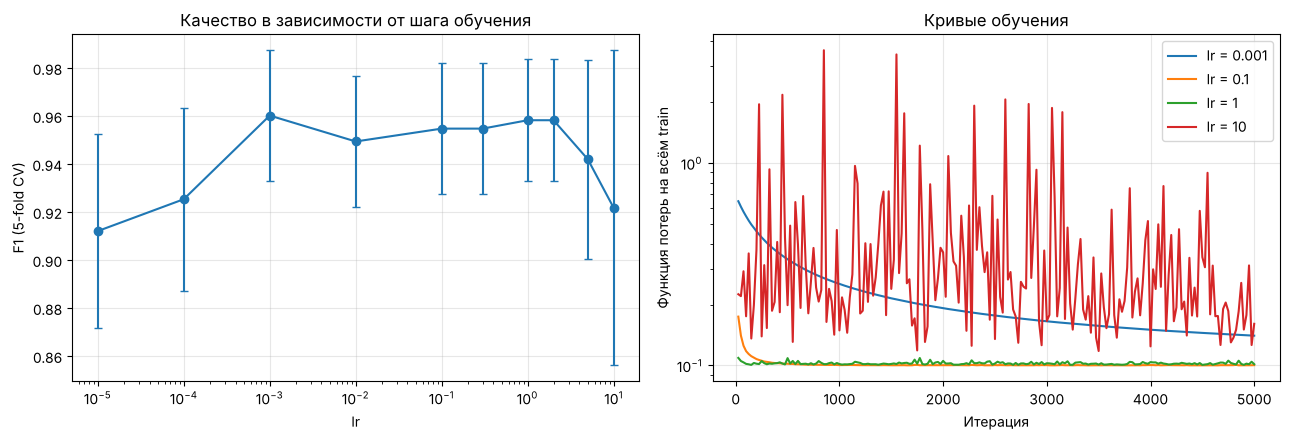

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].errorbar(lr_table["lr"], lr_table["F1"], yerr=lr_table["F1 std"], marker="o", capsize=3)
axes[0].set_xscale("log")
axes[0].set_xlabel("lr")
axes[0].set_ylabel("F1 (5-fold CV)")
axes[0].set_title("Качество в зависимости от шага обучения")

X_scaled = StandardScaler().fit_transform(X_train)
for lr in [1e-3, 0.1, 1, 10]:
    model = SGDLogisticRegression(alpha=0.01, lr=lr, max_iter=5000,
                                  random_state=SEED, record_every=25).fit(X_scaled, y_train)
    steps, losses = zip(*model.loss_history_)
    axes[1].plot(steps, losses, label=f"lr = {lr}")
axes[1].set_yscale("log")
axes[1].set_xlabel("Итерация")
axes[1].set_ylabel("Функция потерь на всём train")
axes[1].set_title("Кривые обучения")
axes[1].legend()
plt.tight_layout()
plt.show()

**Выводы по шагу обучения:**

- При очень малых шагах (`1e-5`, `1e-4`) модель не успевает обучиться за 5000 итераций: F1 около 0.91–0.93, а кривая потерь для `lr = 0.001` ещё не вышла на плато.
- В диапазоне от `1e-3` до `2` качество стабильно высокое (F1 ≈ 0.95–0.96). Различия внутри этого диапазона меньше стандартного отклонения между фолдами (≈ 0.03), поэтому какое-то одно значение лучшим назвать нельзя.
- При больших шагах (`5`, `10`) качество падает, а разброс растёт: веса «прыгают» вокруг хорошего решения и не могут в него точно попасть (красная кривая справа).
- При этом модель при больших `lr` не разваливается совсем. Причина не в шуме мини-батчей, а в том, что градиент логистической потери ограничен: $|\sigma(z) - y| \le 1$, а признаки стандартизованы. Каждый шаг по величине ограничен значением порядка $\text{lr}\cdot\|x\|$, поэтому веса растут не быстрее линейного закона. Сам шум мини-батчей, наоборот, добавляет нестабильности: чем больше `lr`, тем сильнее «дрожит» кривая потерь.

Экспоненциальное расхождение возникает по другой причине, связанной с регуляризацией. Об этом ниже.

## 6. Влияние коэффициента регуляризации (`alpha`)

Сравним модель без регуляризации и модели с разными `alpha`. Шаг фиксируем: `lr = 0.1`.

In [8]:
alphas = [0, 1e-3, 1e-2, 0.1, 1, 10]
rows = []
for alpha in alphas:
    res = cross_validate(make_pipeline(alpha=alpha, lr=0.1, max_iter=5000),
                         X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"alpha": alpha,
                 "F1": res["test_f1"].mean(), "recall": res["test_recall"].mean(),
                 "precision": res["test_precision"].mean()})
alpha_table = pd.DataFrame(rows)
alpha_table.round(4)

,alpha,F1,recall,precision
0,0.000,0.9623,0.9536,0.9716
1,0.001,0.9591,0.9536,0.9651
2,0.010,0.9548,0.9358,0.9749
3,0.100,0.9473,0.9065,0.9929
4,1.000,0.9016,0.8254,0.9939
5,10.000,0.4365,0.2847,0.9765


### Почему важно правильно выбрать положительный класс

Посмотрим на модель с очень сильной регуляризацией (`alpha = 10`) глазами «неправильной» и «правильной» метрики. Используем out-of-fold предсказания на train.

In [9]:
pred_oof = cross_val_predict(make_pipeline(alpha=10, lr=0.1, max_iter=5000), X_train, y_train, cv=cv)

print(f"F1 по классу «доброкачественная» (то, что считалось бы с метками из датасета): "
      f"{f1_score(y_train, pred_oof, pos_label=0):.3f}")
print(f"F1 по классу «злокачественная» (то, что нам нужно): "
      f"{f1_score(y_train, pred_oof, pos_label=1):.3f}")
print(f"Recall по злокачественным: {recall_score(y_train, pred_oof):.3f}")

F1 по классу «доброкачественная» (то, что считалось бы с метками из датасета): 0.821
F1 по классу «злокачественная» (то, что нам нужно): 0.443
Recall по злокачественным: 0.288


**Выводы по регуляризации:**

- На этих данных регуляризация **не улучшает** качество. Лучшее среднее F1 у модели без регуляризации (0.962), но разница с `alpha ≤ 0.01` (0.955–0.959) намного меньше стандартного отклонения между фолдами (≈ 0.025). Объектов достаточно (455) по сравнению с числом признаков (30), а классы почти линейно разделимы, поэтому переобучения практически нет.
- С ростом `alpha` precision растёт, а recall падает: при `alpha = 1` recall равен 0.83 против 0.95 без регуляризации. Для медицинской задачи это плохой размен, ведь мы начинаем пропускать больных.
- При `alpha = 10` модель недообучается и почти всем отвечает «доброкачественная» (recall ≈ 0.29). По метрике для класса «доброкачественная» она при этом выглядела бы вполне прилично (F1 0.82), потому что этот класс в данных преобладает. Поэтому так важно считать метрики по правильному положительному классу.

### Условие устойчивости: lr · alpha < 2

In [10]:
rows = []
for product in [0.5, 1.5, 1.9, 2.1, 3, 10]:
    alpha = product / 0.1                       # lr = 0.1
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore")
        model = SGDLogisticRegression(alpha=alpha, lr=0.1, max_iter=2000,
                                      random_state=SEED).fit(X_scaled, y_train)
    rows.append({"lr * alpha": product, "alpha": alpha,
                 "норма весов ||w||": np.linalg.norm(model.weights_)})

pd.DataFrame(rows)

,lr * alpha,alpha,норма весов ||w||
0,0.5,5.0,6.142633e-01
1,1.5,15.0,5.792690e-01
2,1.9,19.0,2.286892e+00
3,2.1,21.0,5.888254e+82
4,3.0,30.0,NaN
5,10.0,100.0,NaN


Регуляризационная часть шага умножает веса на $(1 - \text{lr}\cdot\alpha)$:

- при $\text{lr}\cdot\alpha < 2$ модуль множителя меньше единицы, и веса сжимаются;
- при $\text{lr}\cdot\alpha > 2$ он больше единицы, и веса растут экспоненциально: при `2.1` норма весов уже порядка $10^{82}$, а при `3` и `10` происходит overflow (`NaN`).

Именно это объясняет «поломку» модели при `alpha = 100` и `lr = 0.1` ($\text{lr}\cdot\alpha = 10$). При $\text{lr}\cdot\alpha$ между 1 и 2 множитель отрицательный, поэтому веса колеблются с переменой знака, а при значениях, близких к 2, затухание медленное и шум градиента накапливается (норма при `1.9` заметно больше, чем при `1.5`). На практике `lr` стоит выбирать так, чтобы $\text{lr}\cdot\alpha$ было заметно меньше 1. Наш класс выдаёт предупреждение, если $\text{lr}\cdot\alpha \ge 2$.

## 7. Выбор `alpha` кросс-валидацией: `KFold` и `ShuffleSplit`

Сравним две стратегии на сетке значений `alpha` (по 5 фолдов/разбиений).

In [11]:
alpha_grid = [1e-4, 1e-3, 1e-2, 0.1, 1]
strategies = {
    "KFold": KFold(n_splits=5, shuffle=True, random_state=SEED),
    "ShuffleSplit": ShuffleSplit(n_splits=5, test_size=0.2, random_state=SEED),
}

rows = []
for alpha in alpha_grid:
    row = {"alpha": alpha}
    for name, splitter in strategies.items():
        scores = cross_val_score(make_pipeline(alpha=alpha, lr=0.1, max_iter=2000),
                                 X_train, y_train, cv=splitter, scoring="f1")
        row[f"{name} F1"] = scores.mean()
        row[f"{name} std"] = scores.std()
    rows.append(row)
pd.DataFrame(rows).round(4)

,alpha,KFold F1,KFold std,ShuffleSplit F1,ShuffleSplit std
0,0.0001,0.9591,0.0258,0.9590,0.0254
1,0.0010,0.9591,0.0258,0.9618,0.0217
2,0.0100,0.9557,0.0239,0.9682,0.0212
3,0.1000,0.9350,0.0317,0.9638,0.0164
4,1.0000,0.9023,0.0274,0.8842,0.0399


Значения `alpha ≤ 0.01` практически неразличимы (F1 0.956–0.968 при std 0.02–0.03). При `0.1` по `KFold` начинается небольшой спад, а `alpha = 1` заметно хуже на обеих стратегиях. Стратегии расходятся в деталях: `KFold` считает лучшими `1e-4` и `1e-3` (F1 0.959), `ShuffleSplit` отдаёт предпочтение `0.01` (0.968). Эти различия меньше шума.

Выбираем **`alpha = 0.001`**: это лучшее значение по `KFold`, оно близко к лучшему по `ShuffleSplit` и сохраняет небольшую регуляризацию.

## 8. Дисперсия оценки качества при кросс-валидации

Для выбранного `alpha = 0.001` повторим кросс-валидацию 100 раз с разными разбиениями (для `KFold` каждый раз включено перемешивание) и посчитаем выборочную дисперсию усреднённого по фолдам значения F1. Сам SGD запускается с одним и тем же seed, поэтому разброс определяется именно способом разбиения данных.

In [12]:
ALPHA = 1e-3
n_repeats = 100

def repeated_cv(make_splitter):
    return np.array([
        cross_val_score(make_pipeline(alpha=ALPHA, lr=0.1, max_iter=2000),
                        X_train, y_train, cv=make_splitter(seed), scoring="f1").mean()
        for seed in range(n_repeats)
    ])

kfold_scores = repeated_cv(lambda s: KFold(n_splits=5, shuffle=True, random_state=s))
shuffle_scores = repeated_cv(lambda s: ShuffleSplit(n_splits=5, test_size=0.2, random_state=s))

summary = pd.DataFrame({
    "среднее F1": [kfold_scores.mean(), shuffle_scores.mean()],
    "дисперсия": [kfold_scores.var(ddof=1), shuffle_scores.var(ddof=1)],
    "std": [kfold_scores.std(ddof=1), shuffle_scores.std(ddof=1)],
}, index=["KFold", "ShuffleSplit"])
summary

,среднее F1,дисперсия,std
KFold,0.961489,0.000032,0.005688
ShuffleSplit,0.960213,0.000088,0.009401


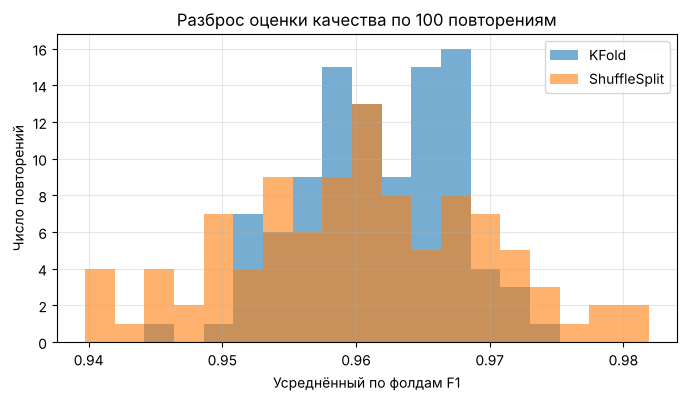

In [13]:
plt.figure(figsize=(8, 4))
bins = np.linspace(min(kfold_scores.min(), shuffle_scores.min()),
                   max(kfold_scores.max(), shuffle_scores.max()), 20)
plt.hist(kfold_scores, bins=bins, alpha=0.6, label="KFold")
plt.hist(shuffle_scores, bins=bins, alpha=0.6, label="ShuffleSplit")
plt.xlabel("Усреднённый по фолдам F1")
plt.ylabel("Число повторений")
plt.title("Разброс оценки качества по 100 повторениям")
plt.legend()
plt.show()

Дисперсия усреднённого F1 у `ShuffleSplit` (8.8·10⁻⁵, std 0.0094) примерно в 2.8 раза больше, чем у `KFold` (3.2·10⁻⁵, std 0.0057), при почти одинаковых средних (0.9602 и 0.9615).

- **KFold.** За один проход каждый объект попадает в валидацию ровно один раз, поэтому оценка использует все данные равномерно и получается устойчивее. Недостатки: размер валидации жёстко связан с числом фолдов (при 5 фолдах это 20%), число разбиений равно числу фолдов, а при сильно несбалансированных классах фолд может случайно получить мало объектов редкого класса. Последнее лечится стратификацией (`StratifiedKFold`).
- **ShuffleSplit.** Валидационные части выбираются независимо, поэтому один объект может попасть в них несколько раз, а другой ни разу. Это и добавляет разброса. Зато можно независимо задавать размер валидации и число разбиений (например, 100 разбиений по 10%).

## 9. Итоговая модель

Обучаем модель на всей обучающей выборке с выбранными гиперпараметрами и **один раз** оцениваем на тесте. Заодно сравниваем с эталоном из sklearn.

In [14]:
final_model = make_pipeline(alpha=ALPHA, lr=0.1, max_iter=5000).fit(X_train, y_train)
pred = final_model.predict(X_test)

reference = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SklearnLogisticRegression(C=1 / (len(X_train) * ALPHA), max_iter=10000)),
]).fit(X_train, y_train)
pred_ref = reference.predict(X_test)

metrics = pd.DataFrame({
    "recall": [recall_score(y_test, pred), recall_score(y_test, pred_ref)],
    "precision": [precision_score(y_test, pred), precision_score(y_test, pred_ref)],
    "F1": [f1_score(y_test, pred), f1_score(y_test, pred_ref)],
}, index=["SGD с нуля", "sklearn"])
display(metrics.round(4))

cm = confusion_matrix(y_test, pred)
print("Матрица ошибок (строки: истина, столбцы: предсказание; порядок: доброкачественная, злокачественная)")
print(cm)
print(f"\nПропущено опухолей (FN): {cm[1, 0]}, ложных тревог (FP): {cm[0, 1]}")

,recall,precision,F1
SGD с нуля,0.9524,0.9756,0.9639
sklearn,0.9524,0.9756,0.9639


Матрица ошибок (строки: истина, столбцы: предсказание; порядок: доброкачественная, злокачественная)
[[71  1]
 [ 2 40]]

Пропущено опухолей (FN): 2, ложных тревог (FP): 1


На тесте итоговая модель даёт recall 0.952, precision 0.976 и F1 0.964, то есть те же значения, что и `LogisticRegression` из sklearn. Из 42 злокачественных опухолей пропущено 2, а из 72 доброкачественных ложной тревогой помечена 1. Тестовая выборка небольшая (114 объектов), поэтому одна ошибка меняет recall примерно на 2.4 п. п., и к этим цифрам надо относиться с поправкой на шум.

### Компромисс между полнотой и точностью

Если пропуск опухоли недопустим, можно снизить порог классификации. Посмотрим, как меняются precision и recall в зависимости от порога. Кривая строится по out-of-fold вероятностям на train, чтобы не подбирать порог по тесту.

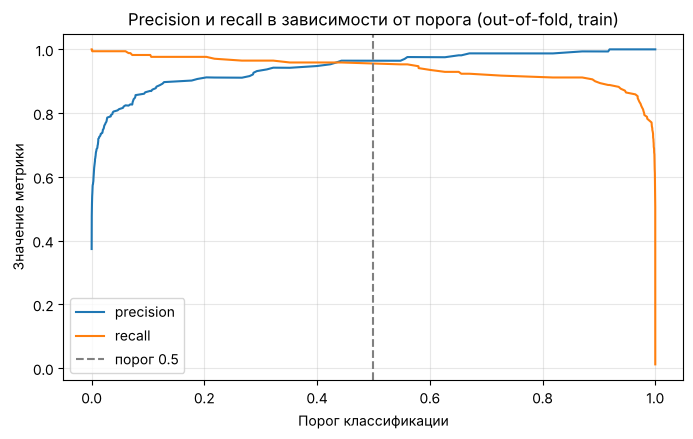

порог 0.5: recall = 0.953, precision = 0.964
порог 0.3: recall = 0.965, precision = 0.937
порог 0.1: recall = 0.982, precision = 0.870


In [15]:
proba_oof = cross_val_predict(make_pipeline(alpha=ALPHA, lr=0.1, max_iter=5000),
                              X_train, y_train, cv=cv, method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, proba_oof)

plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.axvline(0.5, color="gray", linestyle="--", label="порог 0.5")
plt.xlabel("Порог классификации")
plt.ylabel("Значение метрики")
plt.title("Precision и recall в зависимости от порога (out-of-fold, train)")
plt.legend()
plt.show()

for t in [0.5, 0.3, 0.1]:
    pred_t = (proba_oof >= t).astype(int)
    print(f"порог {t}: recall = {recall_score(y_train, pred_t):.3f}, "
          f"precision = {precision_score(y_train, pred_t):.3f}")

Снижение порога повышает recall ценой precision. На out-of-fold предсказаниях при пороге `0.3` recall растёт с 0.953 до 0.965 (precision падает с 0.964 до 0.937), а при `0.1` доходит до 0.982 (precision 0.870). Какой порог выбрать, зависит от того, сколько ложных тревог мы готовы принять ради того, чтобы не пропустить опухоль. В реальной задаче это решение принимается вместе с врачами.

## Выводы

1. **Метки.** В датасете `0` — злокачественная опухоль. Чтобы метрики scikit-learn отвечали на нужный вопрос, положительным классом нужно сделать то, что мы ищем. После инверсии меток `recall` означает «долю найденных опухолей». На примере сильно регуляризованной модели видно разницу: F1 по «доброкачественному» классу 0.82, по «злокачественному» всего 0.44.
2. **Реализация.** Модель с нуля совпадает с эталоном из sklearn: 99.8% совпадающих предсказаний на train и идентичные метрики на тесте.
3. **Шаг обучения.** Слишком малый `lr` ведёт к недообучению, слишком большой добавляет шум и ухудшает качество, но сам по себе расхождения не вызывает, так как градиент логистической потери ограничен.
4. **Регуляризация.** Расхождение (overflow) возникает при $\text{lr}\cdot\alpha > 2$ из-за множителя $(1 - \text{lr}\cdot\alpha)$. На этих данных регуляризация качество не улучшает, а при больших `alpha` снижает recall.
5. **Кросс-валидация.** `KFold` даёт заметно меньшую дисперсию оценки, чем `ShuffleSplit` (примерно в 2.8 раза), но менее гибок в выборе размера валидации.
6. **Воспроизводимость.** Выбор батчей управляется `random_state`, поэтому повторный запуск даёт те же числа. В исходных экспериментах без фиксации seed результаты менялись от запуска к запуску.
7. **Итог.** На тесте recall 0.952, precision 0.976, F1 0.964 (пропущено 2 опухоли из 42).

## Что можно улучшить

- Использовать `StratifiedKFold` и подбирать `lr` и `alpha` совместно (`GridSearchCV` по сетке).
- Добавить затухание шага (learning rate decay) и критерий остановки по сходимости.
- Подбирать порог классификации под требуемый уровень recall.
- Сравнить с другими моделями (SVM, градиентный бустинг) и проверить калибровку вероятностей.